# Bank Marketing: Who Should the Call Center Call?

## Business context

A Portuguese retail bank sells **term deposits** through outbound phone campaigns. Each call costs agent time,
and only about **1 in 9 calls** ends in a subscription. If the bank could rank customers by how likely they are to
subscribe *before* calling, it could:

- call fewer people for the same number of subscriptions, or
- reach more subscribers with the same call-center capacity.

## What this notebook does

| Step | Section | Question it answers |
| --- | --- | --- |
| 1 | Setup | Libraries, random seed, shared settings |
| 2 | Data overview | What is in the data? Any missing values? |
| 3 | Exploratory analysis | Which customer groups subscribe more often? |
| 4 | Leakage check | Which columns would not be available before the call? |
| 5 | Split and preprocessing | How do we turn raw columns into model inputs without leaking test data? |
| 6 | Model comparison | Which algorithm ranks customers best under the same cross-validation? |
| 7 | Class imbalance | Does oversampling / SMOTE help when it is evaluated correctly? |
| 8 | Feature selection | Can we drop weak features without losing accuracy? |
| 9 | Test-set evaluation | How well does the chosen model do on customers it has never seen? |
| 10 | Threshold selection | Where should the call/no-call cut-off be, given call cost vs. subscription value? |
| 11 | Cumulative gains | If we call the top X% of the ranking, what share of subscribers do we reach? |
| 12 | Explainability | Which inputs drive the prediction? |
| 13 | Summary and limitations | What to tell the business, and what this analysis cannot claim |

**Data:** UCI Bank Marketing dataset (`bank-full.csv`): 45,211 calls from May 2008 to November 2010, 16 input
columns, target `y` = did the client subscribe (yes/no).

> Project history: started as a 6-person team project for *Machine Learning with Python* (Santa Clara University,
> Winter 2026) and later extended into this final version.

## 1. Setup

- One random seed (`RANDOM_STATE = 42`) is used everywhere so every number in this notebook is reproducible.
- One cross-validation splitter (`CV`) is shared by every model, so all models are compared on exactly the same folds.
- `savefig()` writes each chart to `../images/` so the README always shows the figures from the latest run.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
    RocCurveDisplay, PrecisionRecallDisplay,
)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler

RANDOM_STATE = 42
DATA_PATH = Path("../data/bank-full.csv")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

def savefig(name):
    plt.tight_layout()
    plt.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Data overview

### Column dictionary

| Column | Type | Meaning |
| --- | --- | --- |
| `age` | numeric | Client age |
| `job` | categorical | Job type (admin., blue-collar, management, retired, student, ...) |
| `marital` | categorical | Marital status |
| `education` | categorical | primary / secondary / tertiary / unknown |
| `default` | categorical | Has credit in default? |
| `balance` | numeric | Average yearly account balance (euros) |
| `housing` | categorical | Has a housing loan? |
| `loan` | categorical | Has a personal loan? |
| `contact` | categorical | Contact channel: cellular / telephone / unknown |
| `day`, `month` | numeric / categorical | Day of month and month of the last contact |
| `duration` | numeric | Length of the last call in seconds (**known only after the call**, see section 4) |
| `campaign` | numeric | Number of contacts in this campaign, including the last one |
| `pdays` | numeric | Days since last contact in a previous campaign (-1 = never contacted) |
| `previous` | numeric | Number of contacts before this campaign |
| `poutcome` | categorical | Outcome of the previous campaign: success / failure / other / unknown |
| `y` | target | Subscribed to a term deposit? yes / no |

The file uses `;` as separator.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
print("Shape:", df.shape)
df.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
target_share = df["y"].value_counts(normalize=True).mul(100).round(1)
print("Target share (%):")
print(target_share)

num_cols_all = df.select_dtypes("number").columns.tolist()
cat_cols_all = df.drop(columns="y").select_dtypes(exclude="number").columns.tolist()
print("\nNumerical:", num_cols_all)
print("Categorical:", cat_cols_all)
print("\nNaN values:", int(df.isna().sum().sum()))

Target share (%):
y
no    88.3000
yes   11.7000
Name: proportion, dtype: float64

Numerical: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

NaN values: 0


In [4]:
df[num_cols_all].describe().T[["mean", "min", "25%", "50%", "75%", "max"]]

,mean,min,25%,50%,75%,max
age,40.9362,18.0000,33.0000,39.0000,48.0000,95.0000
balance,1362.2721,-8019.0000,72.0000,448.0000,1428.0000,102127.0000
day,15.8064,1.0000,8.0000,16.0000,21.0000,31.0000
duration,258.1631,0.0000,103.0000,180.0000,319.0000,4918.0000
campaign,2.7638,1.0000,1.0000,2.0000,3.0000,63.0000
pdays,40.1978,-1.0000,-1.0000,-1.0000,-1.0000,871.0000
previous,0.5803,0.0000,0.0000,0.0000,0.0000,275.0000


**Observations**

- The target is imbalanced: about 88% "no" and 12% "yes". Accuracy is therefore a poor metric (predicting "no" for
  everyone is already 88% accurate). We use **ROC-AUC** and **PR-AUC** instead.
- `balance`, `campaign`, `pdays` and `previous` are heavily right-skewed (medians far below the maxima).
  Tree models are not affected by this; for logistic regression the features are standardized.

### Missing values hide as `"unknown"`

There are no NaNs, but several categorical columns use the literal string `"unknown"`.

In [5]:
unknown = (df[cat_cols_all] == "unknown").mean().mul(100).round(2)
print("Share of 'unknown' (%):")
print(unknown[unknown > 0].sort_values(ascending=False))

rate_by_contact = (df.assign(sub=df["y"].eq("yes"))
                     .groupby("contact")["sub"].agg(["count", "mean"])
                     .rename(columns={"mean": "subscribe_rate"}))
rate_by_contact

Share of 'unknown' (%):
poutcome    81.7500
contact     28.8000
education    4.1100
job          0.6400
dtype: float64


,count,subscribe_rate
contact,,
cellular,29285,0.1492
telephone,2906,0.1342
unknown,13020,0.0407


Clients whose contact type is `"unknown"` subscribe at about **4%**, versus about **15%** for cellular.
"Unknown" is therefore informative in itself, so we keep it as a separate category rather than filling it with the
most common value. Likewise `poutcome = "unknown"` simply means the client was not in a previous campaign.

In [6]:
# pdays = -1 means "never contacted before"; check it lines up with previous = 0
print("pdays == -1 exactly when previous == 0:",
      ((df["pdays"] == -1) == (df["previous"] == 0)).all())

pdays == -1 exactly when previous == 0: True


The two columns agree on every row, so `pdays = -1` is a code for "no previous contact", not a data error.

## 3. Exploratory analysis: who subscribes?

Before modeling, we look at subscription rates across a few groups to see which signals the models might pick up.

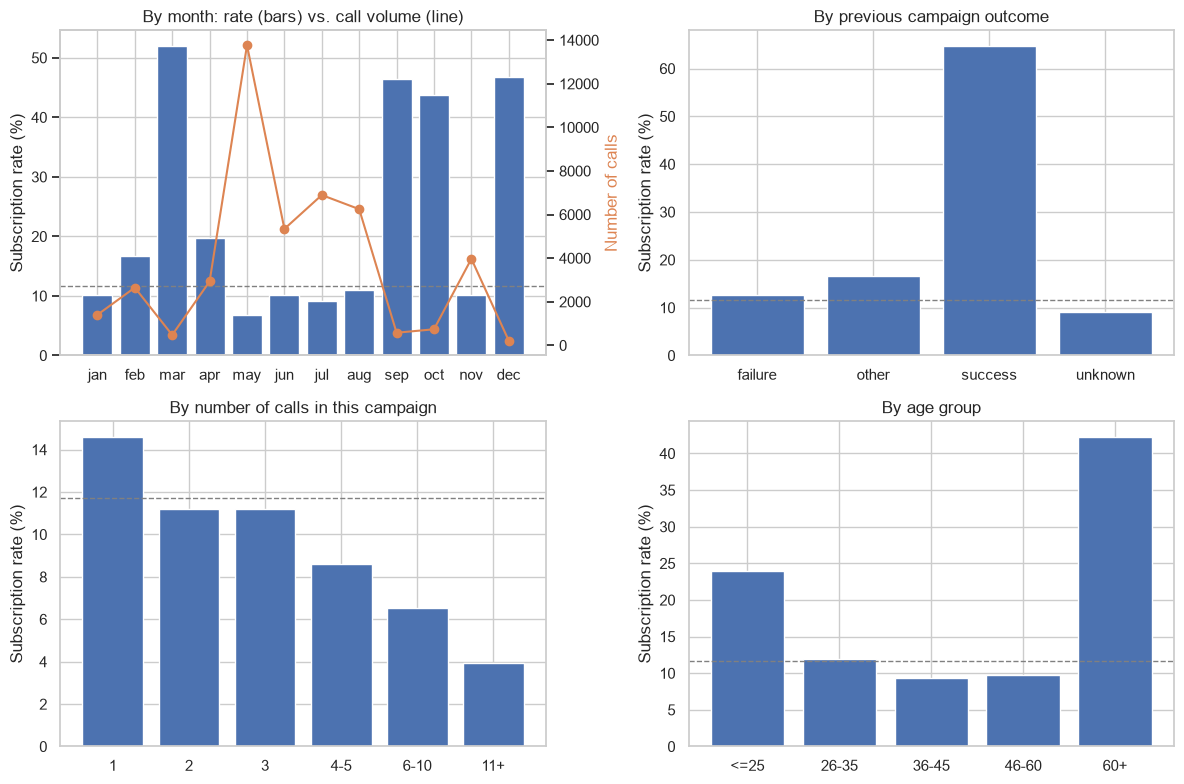

In [7]:
sub = df["y"].eq("yes")
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

by_month = df.assign(sub=sub).groupby("month")["sub"].agg(calls="count", rate="mean").loc[MONTH_ORDER]
by_poutcome = df.assign(sub=sub).groupby("poutcome")["sub"].agg(calls="count", rate="mean")
by_campaign = (df.assign(sub=sub,
                         bucket=pd.cut(df["campaign"], [0, 1, 2, 3, 5, 10, 100],
                                       labels=["1", "2", "3", "4-5", "6-10", "11+"]))
                 .groupby("bucket", observed=True)["sub"].agg(calls="count", rate="mean"))
by_age = (df.assign(sub=sub,
                    bucket=pd.cut(df["age"], [0, 25, 35, 45, 60, 100],
                                  labels=["<=25", "26-35", "36-45", "46-60", "60+"]))
            .groupby("bucket", observed=True)["sub"].agg(calls="count", rate="mean"))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
base = sub.mean() * 100

ax = axes[0, 0]
ax.bar(by_month.index, by_month["rate"] * 100, color="#4C72B0")
ax2 = ax.twinx()
ax2.plot(by_month.index, by_month["calls"], color="#DD8452", marker="o")
ax2.set_ylabel("Number of calls", color="#DD8452")
ax2.grid(False)
ax.set_ylabel("Subscription rate (%)")
ax.set_title("By month: rate (bars) vs. call volume (line)")

for ax, tbl, title in [(axes[0, 1], by_poutcome, "By previous campaign outcome"),
                       (axes[1, 0], by_campaign, "By number of calls in this campaign"),
                       (axes[1, 1], by_age, "By age group")]:
    ax.bar(tbl.index.astype(str), tbl["rate"] * 100, color="#4C72B0")
    ax.set_ylabel("Subscription rate (%)")
    ax.set_title(title)

for ax in axes.flat:
    ax.axhline(base, ls="--", color="grey", lw=1)
savefig("eda_subscription_rates")

In [8]:
print("Subscription rate by month (sorted):")
print(by_month.sort_values("rate").round(3))

Subscription rate by month (sorted):
       calls   rate
month              
may    13766 0.0670
jul     6895 0.0910
jan     1403 0.1010
nov     3970 0.1020
jun     5341 0.1020
aug     6247 0.1100
feb     2649 0.1660
apr     2932 0.1970
oct      738 0.4380
sep      579 0.4650
dec      214 0.4670
mar      477 0.5200


**What the charts show**

- **Month:** the busiest month (May, about 13,800 calls) has the lowest rate (about 7%), while the quietest months
  (March, September, October, December, a few hundred calls each) convert at 44% to 52%. Month seems to reflect
  *how intense the campaign was* more than seasonality: low-volume months were probably targeted at warmer leads.
- **Previous outcome:** clients who said yes in a previous campaign subscribe again about 65% of the time, versus
  9% to 17% for everyone else. This is the strongest single signal in the raw data.
- **Number of calls:** the rate falls steadily from about 15% on the first call to about 4% after more than ten
  calls. Repeatedly calling the same person has diminishing returns.
- **Age:** clients aged 25 and under (about 24%, many of them students) and over 60 (about 42%) subscribe far more
  often than working-age clients (about 9% to 12%).

Dashed lines mark the overall rate (11.7%).

## 4. Leakage check and feature set

`duration` is the length of the current call. It is the most predictive column in the dataset, but it is only
known **after** the call has ended (a 0-second call is always a "no"). A model that uses it cannot be used to
decide whom to call, so it is dropped. The UCI dataset description gives the same advice for realistic models.

All other columns are known before the call is placed, which leaves **15 features**.

In [9]:
y = df["y"].eq("yes").astype(int)
X = df.drop(columns=["y", "duration"])

NUM_COLS = X.select_dtypes("number").columns.tolist()
CAT_COLS = X.select_dtypes(exclude="number").columns.tolist()
print(f"{X.shape[1]} features: {len(NUM_COLS)} numerical, {len(CAT_COLS)} categorical")
print("Numerical:  ", NUM_COLS)
print("Categorical:", CAT_COLS)

15 features: 6 numerical, 9 categorical
Numerical:   ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 5. Train/test split and preprocessing

**Split.** 80% train / 20% test, stratified so both sets keep the 11.7% positive rate. The test set is put aside
and used **once**, in section 9. Every modeling decision before that is made with cross-validation on the training set.

**Preprocessing.** Wrapped in a scikit-learn `ColumnTransformer` inside a `Pipeline`, so it is re-fitted inside each
CV fold and never sees validation or test rows:

| Column type | Step 1 | Step 2 |
| --- | --- | --- |
| Numerical | Median imputation (safety net; there are no NaNs) | Standardization (mean 0, std 1) |
| Categorical | Most-frequent imputation (safety net) | One-hot encoding, `handle_unknown="ignore"` |

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, f"positive {y_train.mean():.1%}")
print("Test: ", X_test.shape, f"positive {y_test.mean():.1%}")
print("The test set is touched only once, in section 9.")

Train: (36168, 15) positive 11.7%
Test:  (9043, 15) positive 11.7%
The test set is touched only once, in section 9.


In [11]:
def make_preprocessor(num_cols, cat_cols):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, num_cols),
        ("cat", categorical, cat_cols),
    ])

n_out = make_preprocessor(NUM_COLS, CAT_COLS).fit_transform(X_train).shape[1]
print("Columns after one-hot encoding:", n_out)

Columns after one-hot encoding: 50


The 9 categorical columns expand into 44 one-hot columns; together with the 6 numerical columns the models see 50 inputs.

## 6. Model comparison with cross-validated tuning

Four algorithms, from simplest to most flexible:

| Model | Why include it | Hyperparameters searched |
| --- | --- | --- |
| Logistic regression | Interpretable linear baseline | `C` (regularization strength) |
| Decision tree | Simple non-linear baseline | `max_depth`, `min_samples_leaf` |
| Random forest | Averages many trees, reduces variance | `max_depth`, `min_samples_leaf` |
| XGBoost | Gradient-boosted trees, usually strongest on tabular data | `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree` |

**How they are compared**

- Same 15 features, same preprocessing, same 5 stratified CV folds.
- `GridSearchCV` picks the best hyperparameters by mean **ROC-AUC** across the folds.
- **PR-AUC** (average precision) is recorded too. With 12% positives, PR-AUC shows how precise the model is among
  the customers it ranks highest, which is what a call center cares about. A random ranking scores about 0.117.
- Class weights are left at their defaults. Imbalance is tested separately in section 7 and handled through the
  decision threshold in section 10.

In [12]:
pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

MODELS = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.05, 0.1, 0.5, 1, 5]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [4, 6, 8, 12],
         "model__min_samples_leaf": [10, 50, 100]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
        {"model__max_depth": [None, 12, 20],
         "model__min_samples_leaf": [5, 10, 20]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
        {"model__n_estimators": [200, 300, 500],
         "model__learning_rate": [0.03, 0.05, 0.1],
         "model__max_depth": [3, 5, 6],
         "model__subsample": [0.8, 1.0],
         "model__colsample_bytree": [0.8, 1.0]},
    ),
}

search = {}
rows = []
for name, (est, grid) in MODELS.items():
    pipe = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)), ("model", est)])
    gs = GridSearchCV(pipe, grid, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                      refit="roc_auc", cv=CV, n_jobs=-1)
    gs.fit(X_train, y_train)
    search[name] = gs
    i = gs.best_index_
    rows.append({
        "model": name,
        "CV ROC-AUC": gs.cv_results_["mean_test_roc_auc"][i],
        "CV ROC-AUC std": gs.cv_results_["std_test_roc_auc"][i],
        "CV PR-AUC": gs.cv_results_["mean_test_pr_auc"][i],
        "best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
    })
    print(f"{name}: {len(gs.cv_results_['params'])} settings x 5 folds done")

cv_table = pd.DataFrame(rows).set_index("model").sort_values("CV ROC-AUC", ascending=False)
cv_table

Logistic Regression: 6 settings x 5 folds done


Decision Tree: 12 settings x 5 folds done


Random Forest: 9 settings x 5 folds done


XGBoost: 108 settings x 5 folds done


,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC,best params
model,,,,
XGBoost,0.8017,0.0029,0.4545,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
Random Forest,0.7950,0.0050,0.4441,"{'max_depth': 20, 'min_samples_leaf': 10}"
Logistic Regression,0.7634,0.0026,0.4027,{'C': 0.05}
Decision Tree,0.7624,0.0049,0.3931,"{'max_depth': 12, 'min_samples_leaf': 100}"


In [13]:
for name, params in cv_table["best params"].items():
    print(f"{name:20s} {params}")

XGBoost              {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.8}
Random Forest        {'max_depth': 20, 'min_samples_leaf': 10}
Logistic Regression  {'C': 0.05}
Decision Tree        {'max_depth': 12, 'min_samples_leaf': 100}


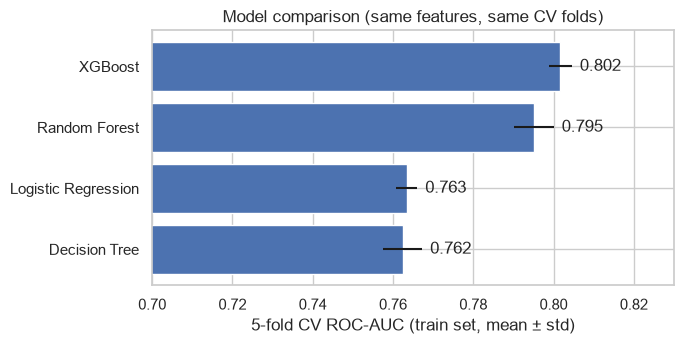

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
plot_df = cv_table.sort_values("CV ROC-AUC")
ax.barh(plot_df.index, plot_df["CV ROC-AUC"], xerr=plot_df["CV ROC-AUC std"], color="#4C72B0")
for i, (v, s) in enumerate(zip(plot_df["CV ROC-AUC"], plot_df["CV ROC-AUC std"])):
    ax.text(v + s + 0.002, i, f"{v:.3f}", va="center")
ax.set_xlim(0.70, 0.83)
ax.set_xlabel("5-fold CV ROC-AUC (train set, mean ± std)")
ax.set_title("Model comparison (same features, same CV folds)")
savefig("model_comparison_cv")

**Reading the result**

- The two tree ensembles clearly beat the single tree and logistic regression (about 0.80 vs 0.76 ROC-AUC),
  which suggests non-linear effects and interactions (e.g. month x contact type) matter.
- XGBoost is ahead of random forest by a small but consistent margin on both ROC-AUC and PR-AUC, with low
  fold-to-fold variation (std about 0.003). XGBoost is carried forward.

## 7. Class imbalance: does resampling help?

A common reflex with imbalanced data is to oversample the minority class (random duplication or SMOTE).
The catch: **resampling must happen inside each CV fold**. If the whole training set is resampled first and then
split into folds, synthetic or duplicated copies of the same customer land in both the training and the validation
fold, and the validation score becomes far too optimistic.

A demonstration of the effect on this dataset follows the comparison table. Everywhere else, an `imblearn`
pipeline applies resampling only to the training part of each fold.

Using the tuned XGBoost settings, four approaches are compared:

| Variant | What it does |
| --- | --- |
| No resampling | Train on the data as is |
| `scale_pos_weight` | Weight each positive by (#negatives / #positives), about 7.5 |
| Random oversampling | Duplicate positives until classes are balanced (inside each fold) |
| SMOTE | Create synthetic positives by interpolating neighbours (inside each fold) |

In [15]:
best_xgb_params = {k.replace("model__", ""): v for k, v in search["XGBoost"].best_params_.items()}

def xgb(**extra):
    return XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
                         **best_xgb_params, **extra)

variants = {
    "No resampling": [("model", xgb())],
    "scale_pos_weight": [("model", xgb(scale_pos_weight=pos_ratio))],
    "Random oversampling (in CV)": [("ros", RandomOverSampler(random_state=RANDOM_STATE)), ("model", xgb())],
    "SMOTE (in CV)": [("smote", SMOTE(random_state=RANDOM_STATE)), ("model", xgb())],
}

imb_rows = []
for name, steps in variants.items():
    pipe = ImbPipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)), *steps])
    auc = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=-1)
    ap = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="average_precision", n_jobs=-1)
    imb_rows.append({"variant": name, "CV ROC-AUC": auc.mean(), "CV PR-AUC": ap.mean()})

imb_table = pd.DataFrame(imb_rows).set_index("variant")
imb_table

,CV ROC-AUC,CV PR-AUC
variant,,
No resampling,0.8017,0.4545
scale_pos_weight,0.7981,0.4484
Random oversampling (in CV),0.7969,0.4469
SMOTE (in CV),0.7803,0.4238


For comparison, the **wrong** way: one-hot encode, SMOTE the whole training set to a 1:1 ratio, *then* cross-validate.

In [16]:
prep_once = make_preprocessor(NUM_COLS, CAT_COLS).fit(X_train)
X_train_enc = prep_once.transform(X_train)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_enc, y_train)

leaky_cv = cross_val_score(xgb(), X_res, y_res, cv=CV, scoring="roc_auc", n_jobs=-1).mean()
leaky_test = roc_auc_score(y_test, xgb().fit(X_res, y_res).predict_proba(prep_once.transform(X_test))[:, 1])

print(f"SMOTE before CV  ->  CV ROC-AUC {leaky_cv:.3f}   but test ROC-AUC {leaky_test:.3f}")
print(f"SMOTE inside CV  ->  CV ROC-AUC {imb_table.loc['SMOTE (in CV)', 'CV ROC-AUC']:.3f}")

SMOTE before CV  ->  CV ROC-AUC 0.964   but test ROC-AUC 0.790
SMOTE inside CV  ->  CV ROC-AUC 0.780


**Result:** resampling before cross-validation produces a CV score that the test set does not confirm, because
validation folds contain synthetic near-copies of training rows. Measured correctly, no resampling method improves
ranking quality; SMOTE is clearly worse
(it invents customers by interpolating one-hot columns, which produces unrealistic profiles).
Resampling mainly pushes predicted probabilities upward, which has the same effect as lowering the decision
threshold. So the plain model is kept, and the trade-off between catching subscribers and wasting calls is set
explicitly through the threshold in section 10.

## 8. Feature selection check

`default`, `job` and `education` showed low importance in early experiments. Do we lose anything by dropping them?
Same model, same folds:

In [17]:
DROP = ["default", "job", "education"]
num_r = [c for c in NUM_COLS if c not in DROP]
cat_r = [c for c in CAT_COLS if c not in DROP]

pipe_reduced = Pipeline([("prep", make_preprocessor(num_r, cat_r)), ("model", xgb())])
auc_reduced = cross_val_score(pipe_reduced, X_train[num_r + cat_r], y_train, cv=CV, scoring="roc_auc", n_jobs=-1)

full_auc = cv_table.loc["XGBoost", "CV ROC-AUC"]
print(f"All 15 features     CV ROC-AUC: {full_auc:.4f} (fold std {cv_table.loc['XGBoost', 'CV ROC-AUC std']:.4f})")
print(f"Reduced 12 features CV ROC-AUC: {auc_reduced.mean():.4f} (fold std {auc_reduced.std():.4f})")
print(f"Difference: {auc_reduced.mean() - full_auc:+.4f}")

All 15 features     CV ROC-AUC: 0.8017 (fold std 0.0029)
Reduced 12 features CV ROC-AUC: 0.8026 (fold std 0.0034)
Difference: +0.0009


The difference is far smaller than the fold-to-fold variation, so the three features neither help nor hurt in a
measurable way. Both versions are defensible; the final model keeps all 15 features so that every model in the
comparison above uses the same inputs.

## 9. Final test-set evaluation

The model with the best CV ROC-AUC (XGBoost) is now evaluated **once** on the 9,043 held-out customers.
All tuned models are shown for context, but the choice was already made on CV results.

In [18]:
best_name = cv_table.index[0]
final_model = search[best_name].best_estimator_
print("Selected by CV:", best_name)

test_rows = []
for name, gs in search.items():
    p = gs.best_estimator_.predict_proba(X_test)[:, 1]
    test_rows.append({"model": name,
                      "Test ROC-AUC": roc_auc_score(y_test, p),
                      "Test PR-AUC": average_precision_score(y_test, p)})
test_table = pd.DataFrame(test_rows).set_index("model").loc[cv_table.index]
summary_table = cv_table[["CV ROC-AUC", "CV PR-AUC"]].join(test_table)
summary_table

Selected by CV: XGBoost


,CV ROC-AUC,CV PR-AUC,Test ROC-AUC,Test PR-AUC
model,,,,
XGBoost,0.8017,0.4545,0.8089,0.4721
Random Forest,0.7950,0.4441,0.8058,0.4547
Logistic Regression,0.7634,0.4027,0.7730,0.4114
Decision Tree,0.7624,0.3931,0.7721,0.4146


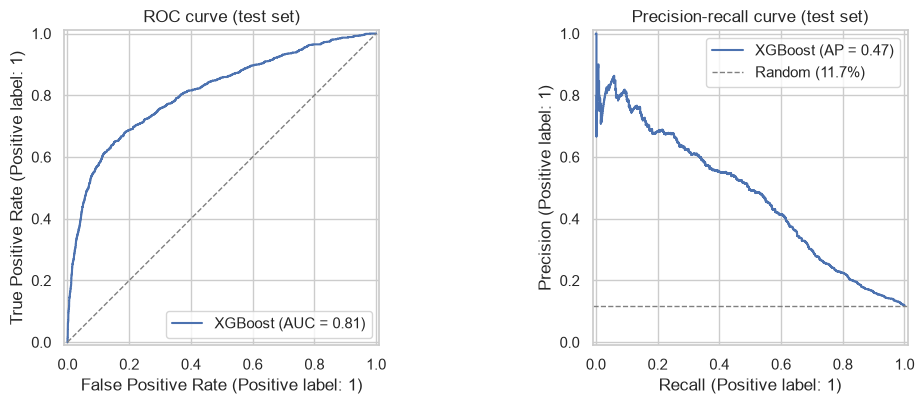

In [19]:
test_prob = final_model.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[0], name=best_name)
axes[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
axes[0].set_title("ROC curve (test set)")
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=best_name)
axes[1].axhline(y_test.mean(), ls="--", color="grey", lw=1, label=f"Random ({y_test.mean():.1%})")
axes[1].legend()
axes[1].set_title("Precision-recall curve (test set)")
savefig("roc_pr_curves")

**Reading the result**

- Test scores are in line with (slightly above) the CV scores, so the model is not overfitting the training data
  and the CV estimates were trustworthy.
- Test PR-AUC is about 0.47, roughly **4 times** the 0.117 a random ranking would get.
- The precision-recall curve shows the trade-off the business has to choose on: at the very top of the ranking
  precision is high, and it falls as we go deeper down the list to catch more subscribers.

## 10. Threshold selection under contact-cost scenarios

A probability score alone does not tell agents whom to call; we need a cut-off ("call if score >= t").
The default of 0.5 is arbitrary. The right cut-off depends on economics.

**Set-up.** Let **C** = cost of one call and **V** = value of one subscription. Calling a customer pays off on
average when the share of subscribers among those called (precision) exceeds C/V. Net value per customer in the base:

$$\text{utility}(t) = \text{outreach rate}(t) \times \big(\text{precision}(t) - C/V\big) \quad \text{(in units of V)}$$

C and V are not in the data, so several ratios from 0.10 to 0.30 are tested.

**Procedure**

1. Split a validation set (20%) off the **training** data and refit the tuned XGBoost on the remaining 80%.
2. Scan thresholds from 0.05 to 0.90 on the validation set and pick the utility-maximising threshold per C/V.
3. Apply each chosen threshold once to the test set to confirm it holds up on new data.

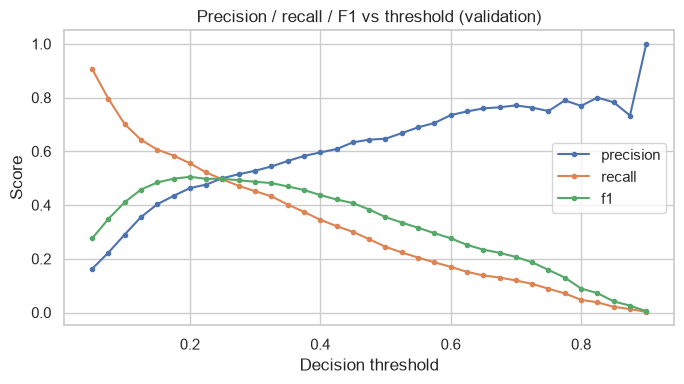

In [20]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)
thr_model = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)), ("model", xgb())]).fit(X_tr, y_tr)
val_prob = thr_model.predict_proba(X_val)[:, 1]

def threshold_table(y_true, prob, thresholds):
    rows = []
    for t in thresholds:
        pred = (prob >= t).astype(int)
        rows.append({"threshold": t,
                     "precision": precision_score(y_true, pred, zero_division=0),
                     "recall": recall_score(y_true, pred, zero_division=0),
                     "f1": f1_score(y_true, pred, zero_division=0),
                     "outreach_rate": pred.mean()})
    return pd.DataFrame(rows)

THRESHOLDS = np.round(np.arange(0.05, 0.91, 0.025), 3)
val_thr = threshold_table(y_val, val_prob, THRESHOLDS)

fig, ax = plt.subplots(figsize=(7, 4))
for col in ["precision", "recall", "f1"]:
    ax.plot(val_thr["threshold"], val_thr[col], marker="o", ms=3, label=col)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / recall / F1 vs threshold (validation)")
ax.legend()
savefig("threshold_tradeoff")

As the threshold rises, precision goes up and recall goes down. F1 peaks around 0.2, far below the default 0.5,
which is typical for a 12%-positive problem.

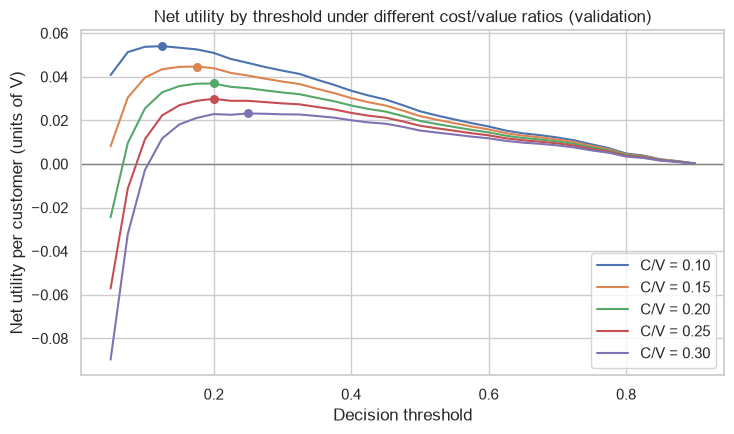

,threshold,val precision,val recall,test precision,test recall,test % of customers called
C/V,,,,,,
0.1000,0.1250,0.3553,0.6430,0.3631,0.6456,20.8006
0.1500,0.1750,0.4341,0.5839,0.4503,0.5614,14.5859
0.2000,0.2000,0.4631,0.5556,0.4774,0.5388,13.2036
0.2500,0.2000,0.4631,0.5556,0.4774,0.5388,13.2036
0.3000,0.2500,0.5000,0.4953,0.5103,0.4905,11.2463


In [21]:
CV_RATIOS = [0.10, 0.15, 0.20, 0.25, 0.30]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
scenario_rows = []
for r in CV_RATIOS:
    util = val_thr["outreach_rate"] * (val_thr["precision"] - r)
    best = val_thr.loc[util.idxmax()]
    ax.plot(val_thr["threshold"], util, label=f"C/V = {r:.2f}")
    ax.scatter(best["threshold"], util.max(), s=30)

    # check the chosen threshold once on the test set
    test_pred = (test_prob >= best["threshold"]).astype(int)
    scenario_rows.append({
        "C/V": r,
        "threshold": best["threshold"],
        "val precision": best["precision"],
        "val recall": best["recall"],
        "test precision": precision_score(y_test, test_pred, zero_division=0),
        "test recall": recall_score(y_test, test_pred),
        "test % of customers called": test_pred.mean() * 100,
    })
ax.axhline(0, color="grey", lw=1)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Net utility per customer (units of V)")
ax.set_title("Net utility by threshold under different cost/value ratios (validation)")
ax.legend()
savefig("net_utility_by_threshold")

scenario_table = pd.DataFrame(scenario_rows).set_index("C/V")
scenario_table

**Reading the result**

- The dots mark the best threshold for each scenario. The cheaper a call is relative to a subscription
  (low C/V), the lower the best threshold and the more customers are worth calling.
- Test precision and recall closely match the validation values, so the chosen thresholds carry over to new data.
- Example: if a call costs 20% of what a subscription is worth (C/V = 0.20), calling only the ~13% of customers
  above a 0.20 score reaches about 54% of all subscribers, and about 48% of the calls convert
  (vs 11.7% if calling at random).
- The C/V ratios are assumptions, so these numbers support a decision rather than estimate profit.

## 11. Cumulative gains: how many subscribers do we reach per call?

A threshold-free way to explain the model to a business audience: sort test customers from highest to lowest
score, call from the top down, and track what share of all subscribers has been reached.

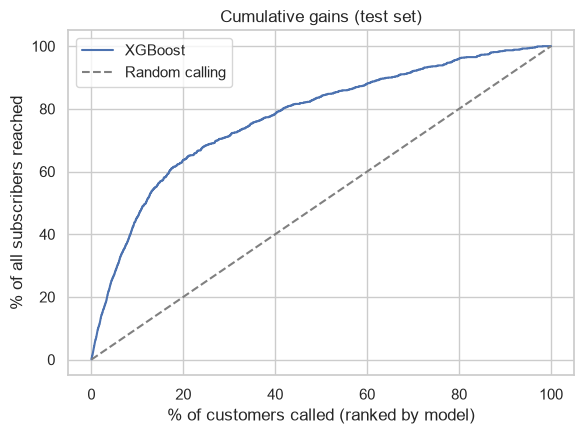

,% of customers called,% of subscribers reached,lift vs random
0,10,45.5000,4.5000
1,20,63.7000,3.2000
2,30,71.4000,2.4000
3,40,78.4000,2.0000
4,50,83.9000,1.7000


In [22]:
order = np.argsort(-test_prob)
captured = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
called = np.arange(1, len(order) + 1) / len(order)

gains = pd.DataFrame({
    "% of customers called": [10, 20, 30, 40, 50],
    "% of subscribers reached": [captured[int(len(order) * p / 100) - 1] * 100 for p in [10, 20, 30, 40, 50]],
})
gains["lift vs random"] = gains["% of subscribers reached"] / gains["% of customers called"]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(called * 100, captured * 100, label=best_name)
ax.plot([0, 100], [0, 100], "--", color="grey", label="Random calling")
ax.set_xlabel("% of customers called (ranked by model)")
ax.set_ylabel("% of all subscribers reached")
ax.set_title("Cumulative gains (test set)")
ax.legend()
savefig("cumulative_gains")
gains.round(1)

Calling the top **10%** of the ranking reaches about **45%** of all subscribers (4.5x random);
the top **20%** reaches about **64%** (3.2x). After that the curve flattens: the remaining subscribers are
hard to tell apart from non-subscribers with the information available before the call.

## 12. What drives the prediction?

**Permutation importance:** shuffle one column at a time in the test set and measure how much test ROC-AUC drops.
It is computed on the **original** 15 columns (not the 50 one-hot dummies), so each categorical variable is scored
as a whole, and it is model-agnostic. Repeated 10 times per column; error bars show the spread.

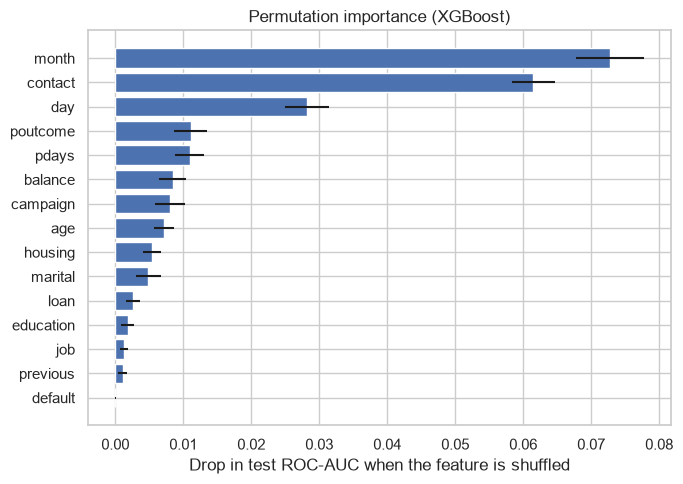

,feature,ROC-AUC drop,std
10,month,0.0728,0.0050
8,contact,0.0615,0.0031
9,day,0.0282,0.0033
14,poutcome,0.0111,0.0024
12,pdays,0.0109,0.0021
5,balance,0.0084,0.0020
11,campaign,0.0081,0.0022
0,age,0.0072,0.0015


In [23]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_test.columns,
                     "ROC-AUC drop": perm.importances_mean,
                     "std": perm.importances_std})
         .sort_values("ROC-AUC drop", ascending=True))

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp["feature"], imp["ROC-AUC drop"], xerr=imp["std"], color="#4C72B0")
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_title(f"Permutation importance ({best_name})")
savefig("feature_importance")
imp.sort_values("ROC-AUC drop", ascending=False).head(8)

**Reading the result**

- `month` and `contact` dominate. As section 3 showed, month mostly captures campaign timing and intensity, and an
  unknown contact channel marks a low-converting group.
- `day` is third. Together with month it pins down *when* in a campaign a call happened.
- `poutcome` and `pdays` (history with previous campaigns) come next, followed by balance, number of calls and age.
- Demographics such as job, education and marital status add little once these are known, consistent with
  section 8.

## 13. Summary and limitations

In [24]:
row = summary_table.loc[best_name]
g10 = gains.loc[gains["% of customers called"] == 10, "% of subscribers reached"].item()
g20 = gains.loc[gains["% of customers called"] == 20, "% of subscribers reached"].item()
top3 = imp.sort_values("ROC-AUC drop", ascending=False)["feature"].head(3).tolist()
print(f"Best model (by CV): {best_name}")
print(f"  CV ROC-AUC {row['CV ROC-AUC']:.3f} | test ROC-AUC {row['Test ROC-AUC']:.3f} | test PR-AUC {row['Test PR-AUC']:.3f} "
      f"(random baseline PR-AUC = {y_test.mean():.3f})")
print(f"  Top 10% of ranked customers -> {g10:.1f}% of subscribers ({g10/10:.1f}x random)")
print(f"  Top 20% of ranked customers -> {g20:.1f}% of subscribers ({g20/20:.1f}x random)")
print(f"  Most important features: {', '.join(top3)}")
print(f"  Resampling inside CV changed CV ROC-AUC by at most "
      f"{(imb_table['CV ROC-AUC'] - imb_table.loc['No resampling', 'CV ROC-AUC']).abs().max():.3f}.")

Best model (by CV): XGBoost
  CV ROC-AUC 0.802 | test ROC-AUC 0.809 | test PR-AUC 0.472 (random baseline PR-AUC = 0.117)
  Top 10% of ranked customers -> 45.5% of subscribers (4.5x random)
  Top 20% of ranked customers -> 63.7% of subscribers (3.2x random)
  Most important features: month, contact, day
  Resampling inside CV changed CV ROC-AUC by at most 0.021.


### Recommendations for the call center

1. **Rank before calling.** Score every customer and work the list from the top. The top fifth of the list holds
   nearly two-thirds of the subscribers.
2. **Set the cut-off from economics, not from 0.5.** Estimate the real cost per call and value per subscription, then
   read the threshold off the utility analysis (section 10).
3. **Prioritise previous subscribers** and cap repeat calls to the same person: conversion falls steadily after
   the first few contacts.

### Limitations

- **Time.** The data covers 2008 to 2010, partly during the financial crisis, and month/day effects reflect that
  bank's campaign calendar. A random split lets the model learn those calendar patterns; a deployment would need a
  time-based split and periodic retraining.
- **Costs are assumed.** The C/V ratios are scenarios, not the bank's real numbers.
- **Correlation, not causation.** The model ranks customers by likelihood; it does not show that calling in a given
  month *causes* a subscription.
- **Single dataset.** Results have not been validated on other banks or later campaigns.